In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("job_data_merged.csv")
df = df.drop(columns=["Unnamed: 0"])
original_shape = df.shape

print("Shape:", df.shape)
print(df.head())
print(df.isnull().sum())
print(df["Workplace"].unique())
print(df["Type"].unique())

Shape: (1095, 5)
           Category Workplace                                      Location  \
0  Business Analyst    Remote                                United Kingdom   
1  Business Analyst    Remote             Makati, Metro Manila, Philippines   
2  Business Analyst   On-site  Al-Dajeej, Al Farwaniyah Governorate, Kuwait   
3  Business Analyst   On-site               London, England, United Kingdom   
4  Business Analyst    Remote                                United Kingdom   

              Department       Type  
0             Operations  Full time  
1                 Aux HQ  Full time  
2       PWC Technologies  Full time  
3  Consultants, Advisory  Full time  
4             Operations  Full time  
Category        0
Workplace      56
Location       68
Department    166
Type          169
dtype: int64
['Remote' 'On-site' 'Hybrid' nan 'Hybride' 'Sur cite']
['Full time' nan 'Contract' 'Other' 'Part time' 'Temporary' 'Temps plein']


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print("\nTop 10 Countries:")
print(df.loc[df["Country"] != "Unknown", "Country"].value_counts().head(10))

print("\nEmployment Type Distribution:")
print(df["Type"].value_counts())

print("\nTop 10 Departments:")
print(df["Department"].value_counts().head(10))

print("\nWorkplace Distribution by Country:")
print(pd.crosstab(df["Country"], df["Workplace"]).head(10))

print("\nDataset Summary:")
print("Total job postings:", len(df))
print("Unique countries:", df.loc[df["Country"] != "Unknown", "Country"].nunique())
print("Unique cities:", df.loc[df["City"] != "Unknown", "City"].nunique())

Duplicate rows: 423

Top 10 Countries:
Country
United States     253
United Kingdom    152
India              92
Philippines        49
Canada             36
Greece             31
Australia          28
Egypt              27
Saudi Arabia       24
Spain              21
Name: count, dtype: int64

Employment Type Distribution:
Type
Full time        850
Not specified    169
Contract          39
Other             14
Temporary         13
Part time         10
Name: count, dtype: int64

Top 10 Departments:
Department
Unknown                   166
Engineering                84
Product                    39
Technology                 30
Sales                      26
Information Technology     21
Data Science               20
Human Resources            17
Development                14
Design                     13
Name: count, dtype: int64

Workplace Distribution by Country:
Workplace   Hybrid  Not specified  On-site  Remote
Country                                           
Australia        3     

In [ ]:
df["Workplace"] = df["Workplace"].apply(clean_workplace)
df["Type"] = df["Type"].apply(clean_type)
df["Department"] = df["Department"].fillna("Unknown")
df["Country"] = df["Location"].apply(get_country)
df["City"] = df["Location"].apply(get_city)

# table with only known countries
known = df[df["Country"] != "Unknown"]

print(df["Workplace"].value_counts())
print(df[["Location", "City", "Country"]].head())
print("Known country rows:", len(known), "of", len(df))

Workplace
On-site          464
Remote           413
Hybrid           162
Not specified     56
Name: count, dtype: int64
                                       Location       City         Country
0                                United Kingdom    Unknown  United Kingdom
1             Makati, Metro Manila, Philippines     Makati     Philippines
2  Al-Dajeej, Al Farwaniyah Governorate, Kuwait  Al-Dajeej          Kuwait
3               London, England, United Kingdom     London  United Kingdom
4                                United Kingdom    Unknown  United Kingdom
Known country rows: 1027 of 1095


In [ ]:
all_categories = df["Category"].tolist()
print("Total items:", len(all_categories))
print("First 5:", all_categories[:5])

category_list = sorted(df["Category"].unique().tolist())
print(category_list)

countries_upper = [c.upper() for c in df["Country"].tolist()]
print(countries_upper[:5])

indian_cities = [city for city, country in zip(df["City"], df["Country"])
                 if country == "India"]
print("Postings in India:", len(indian_cities))

category_list.append("Test")
category_list.remove("Test")
print(category_list)

Total items: 1095
First 5: ['Business Analyst', 'Business Analyst', 'Business Analyst', 'Business Analyst', 'Business Analyst']
['Business Analyst', 'Cloud', 'Data Scientist', 'HR', 'Software Developer', 'UI/UX']
['UNITED KINGDOM', 'PHILIPPINES', 'KUWAIT', 'UNITED KINGDOM', 'UNITED KINGDOM']
Postings in India: 92
['Business Analyst', 'Cloud', 'Data Scientist', 'HR', 'Software Developer', 'UI/UX']


In [ ]:
top_countries = known["Country"].value_counts().head(5)
top_5_tuples = [(country, count) for country, count in top_countries.items()]
print(top_5_tuples)

best_country, best_count = top_5_tuples[0]
print(f"Best country = {best_country}, postings = {best_count}")

rows, cols = original_shape
print(f"Dataset has {rows} rows and {cols} columns")

WORKPLACE_TYPES = ("Remote", "Hybrid", "On-site")


def min_max_category(dataframe):
    counts = dataframe["Category"].value_counts()
    return counts.idxmax(), counts.idxmin()


most_cat, least_cat = min_max_category(df)
print("Most postings :", most_cat)
print("Least postings:", least_cat)

[('United States', 253), ('United Kingdom', 152), ('India', 92), ('Philippines', 49), ('Canada', 36)]
Best country = United States, postings = 253
Dataset has 1095 rows and 5 columns
Most postings : UI/UX
Least postings: Cloud


In [ ]:
# 1. Count manually
category_count = {}
for cat in df["Category"]:
    if cat in category_count:
        category_count[cat] += 1
    else:
        category_count[cat] = 1
print(category_count)
remote_pct = {
    cat: round(float((df[df["Category"] == cat]["Workplace"] == "Remote").mean() * 100), 1)
    for cat in category_list
}
print(remote_pct)
nested = {}
for cat in category_list:
    nested[cat] = df[df["Category"] == cat]["Workplace"].value_counts().to_dict()
for cat, inner in nested.items():
    print(f"{cat:<20} {inner}")
sorted_remote = dict(sorted(remote_pct.items(), key=lambda kv: kv[1], reverse=True))
print(sorted_remote)
print(list(category_count.keys()))
print(list(category_count.values()))

{'Business Analyst': 175, 'Cloud': 170, 'Data Scientist': 190, 'HR': 180, 'Software Developer': 189, 'UI/UX': 191}
{'Business Analyst': 25.1, 'Cloud': 38.2, 'Data Scientist': 37.4, 'HR': 31.1, 'Software Developer': 37.0, 'UI/UX': 56.0}
Business Analyst     {'On-site': 90, 'Remote': 44, 'Hybrid': 38, 'Not specified': 3}
Cloud                {'Remote': 65, 'On-site': 62, 'Hybrid': 33, 'Not specified': 10}
Data Scientist       {'On-site': 83, 'Remote': 71, 'Hybrid': 24, 'Not specified': 12}
HR                   {'On-site': 96, 'Remote': 56, 'Hybrid': 21, 'Not specified': 7}
Software Developer   {'On-site': 83, 'Remote': 70, 'Hybrid': 21, 'Not specified': 15}
UI/UX                {'Remote': 107, 'On-site': 50, 'Hybrid': 25, 'Not specified': 9}
{'UI/UX': 56.0, 'Cloud': 38.2, 'Data Scientist': 37.4, 'Software Developer': 37.0, 'HR': 31.1, 'Business Analyst': 25.1}
['Business Analyst', 'Cloud', 'Data Scientist', 'HR', 'Software Developer', 'UI/UX']
[175, 170, 190, 180, 189, 191]


In [ ]:
cats = np.array(list(category_count.keys()))
counts = np.array(list(category_count.values()))

print("Total  :", np.sum(counts))
print("Mean   :", round(np.mean(counts), 2))
print("Median :", np.median(counts))
print("Std    :", round(np.std(counts), 2))
print("Max/Min:", np.max(counts), "/", np.min(counts))
print("Category with max:", cats[np.argmax(counts)])

share = np.round(counts / counts.sum() * 100, 2)
print(dict(zip(cats.tolist(), share.tolist())))

print("Above average:", cats[counts > counts.mean()])

df["RemoteFriendly"] = np.where(df["Workplace"].isin(["Remote", "Hybrid"]), 1, 0)
print("Remote-friendly:", df["RemoteFriendly"].sum(),
      f"({df['RemoteFriendly'].mean() * 100:.1f}%)")

matrix = np.array([[nested[c].get(w, 0) for w in WORKPLACE_TYPES]
                   for c in category_list])
print(matrix)
print("Column totals:", matrix.sum(axis=0))
print("Row totals   :", matrix.sum(axis=1))

Total  : 1095
Mean   : 182.5
Median : 184.5
Std    : 8.06
Max/Min: 191 / 170
Category with max: UI/UX
{'Business Analyst': 15.98, 'Cloud': 15.53, 'Data Scientist': 17.35, 'HR': 16.44, 'Software Developer': 17.26, 'UI/UX': 17.44}
Above average: ['Data Scientist' 'Software Developer' 'UI/UX']
Remote-friendly: 575 (52.5%)
[[ 44  38  90]
 [ 65  33  62]
 [ 71  24  83]
 [ 56  21  96]
 [ 70  21  83]
 [107  25  50]]
Column totals: [413 162 464]
Row totals   : [172 160 178 173 174 182]


In [ ]:
print(df["Category"].value_counts())

print(known["Country"].value_counts().head(10))

print(df[df["City"] != "Unknown"]["City"].value_counts().head(5))

crosstab = pd.crosstab(df["Category"], df["Workplace"])
print(crosstab)

rf = df.groupby("Category")["RemoteFriendly"].mean().mul(100).round(1)
print(rf.sort_values(ascending=False))

print(pd.crosstab(df["Category"], df["Type"]))

print(df[df["Department"] != "Unknown"]["Department"].value_counts().head(5))

filtered = df[(df["Category"] == "Data Scientist") &
              (df["Workplace"] == "Remote") &
              (df["Country"] == "India")]
print(len(filtered), "postings found")

Category
UI/UX                 191
Data Scientist        190
Software Developer    189
HR                    180
Business Analyst      175
Cloud                 170
Name: count, dtype: int64
Country
United States     253
United Kingdom    152
India              92
Philippines        49
Canada             36
Greece             31
Australia          28
Egypt              27
Saudi Arabia       24
Spain              21
Name: count, dtype: int64
City
London       84
Bengaluru    29
New York     28
Gurugram     24
Athens       23
Name: count, dtype: int64
Workplace           Hybrid  Not specified  On-site  Remote
Category                                                  
Business Analyst        38              3       90      44
Cloud                   33             10       62      65
Data Scientist          24             12       83      71
HR                      21              7       96      56
Software Developer      21             15       83      70
UI/UX                   25     

In [ ]:
import io, base64
import matplotlib.pyplot as plt

charts = []
_orig_show = plt.show

def show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
        charts.append(base64.b64encode(buf.getvalue()).decode())
    _orig_show(*args, **kwargs)

plt.show = show_and_save

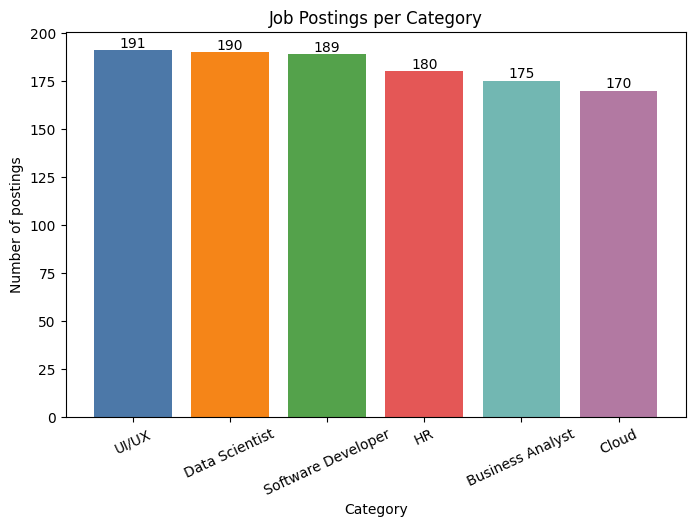

In [ ]:
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#B279A2"]

cat_counts = df["Category"].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(cat_counts.index, cat_counts.values, color=colors)
ax.bar_label(bars)
ax.set_title("Job Postings per Category")
ax.set_xlabel("Category")
ax.set_ylabel("Number of postings")
plt.xticks(rotation=25)
plt.show()

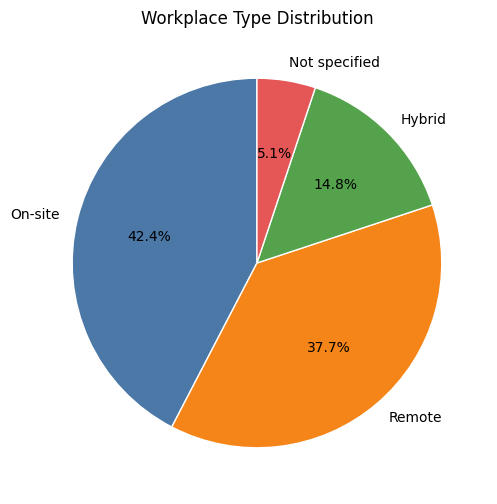

In [ ]:
wp = df["Workplace"].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(wp.values, labels=wp.index, autopct="%1.1f%%", startangle=90,
       colors=colors, wedgeprops={"edgecolor": "white"})
ax.set_title("Workplace Type Distribution")
plt.show()

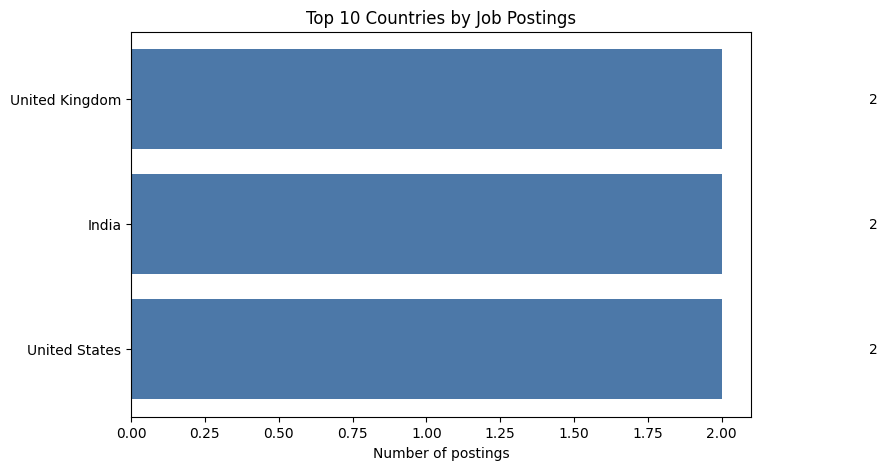

In [ ]:
top10 = known["Country"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10.values, color="#4C78A8")
ax.set_title("Top 10 Countries by Job Postings")
ax.set_xlabel("Number of postings")
for i, v in enumerate(top10.values):
    ax.text(v + 0.5, i, str(v), va="center")
plt.show()

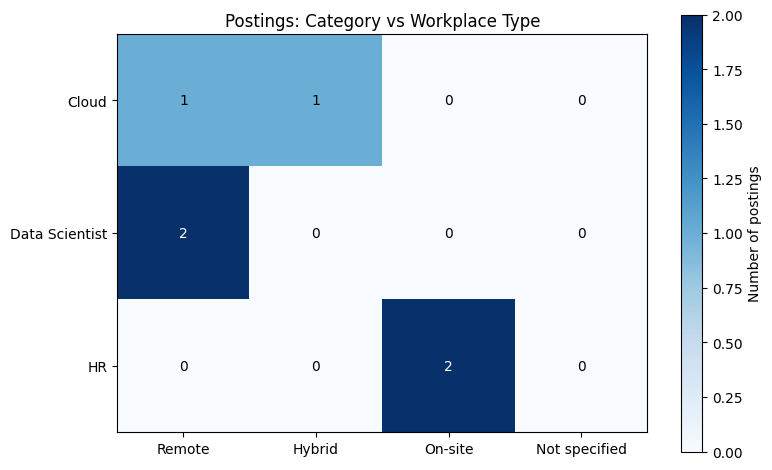

In [ ]:
wp_order = ["Remote", "Hybrid", "On-site", "Not specified"]
ct = pd.crosstab(df["Category"], df["Workplace"]).reindex(columns=wp_order, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(len(ct.columns)))
ax.set_xticklabels(ct.columns)
ax.set_yticks(range(len(ct.index)))
ax.set_yticklabels(ct.index)

# write the count inside every cell
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        value = ct.values[i, j]
        ax.text(j, i, value, ha="center", va="center",
                color="white" if value > ct.values.max() / 2 else "black")

ax.set_title("Postings: Category vs Workplace Type")
plt.colorbar(im, label="Number of postings")
plt.tight_layout()
plt.show()

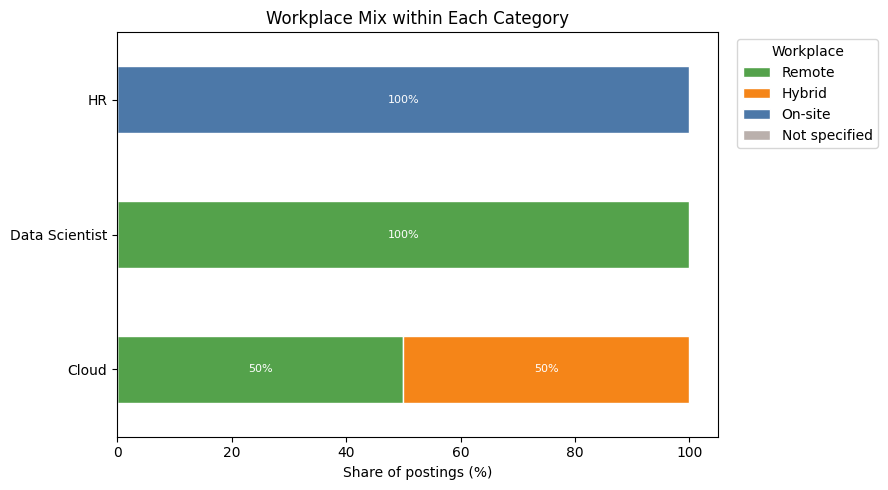

In [ ]:
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

ax = ct_pct.plot(kind="barh", stacked=True, figsize=(9, 5),
                 color=["#54A24B", "#F58518", "#4C78A8", "#BAB0AC"],
                 edgecolor="white")
ax.set_xlabel("Share of postings (%)")
ax.set_ylabel("")
ax.set_title("Workplace Mix within Each Category")
ax.legend(title="Workplace", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    labels = [f"{v:.0f}%" if v >= 8 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=8)
plt.tight_layout()
plt.show()

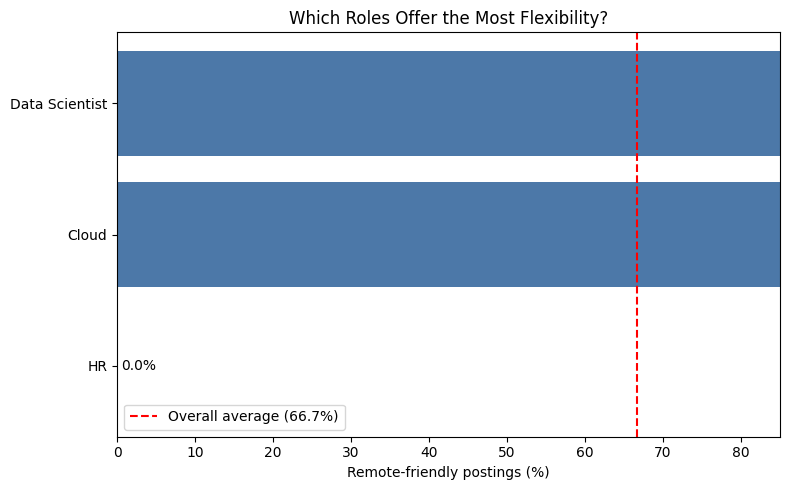

In [ ]:
rf_sorted = df.groupby("Category")["RemoteFriendly"].mean().mul(100).sort_values()
overall = df["RemoteFriendly"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rf_sorted.index, rf_sorted.values, color="#4C78A8")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.axvline(overall, color="red", linestyle="--", label=f"Overall average ({overall:.1f}%)")
ax.set_xlabel("Remote-friendly postings (%)")
ax.set_title("Which Roles Offer the Most Flexibility?")
ax.set_xlim(0, 85)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
%%writefile index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Where the Jobs Are: Job Postings Analysis, Group 3</title>
<style>
:root{
  --bg:#f3f6f8;--surface:#ffffff;--ink:#14232e;--muted:#52636f;--line:#d5dee4;
  --onsite:#3e5c76;--remote:#16897c;--hybrid:#d98f1f;--none:#a9b4bd;--accent:#16897c;
}
@media (prefers-color-scheme:dark){
  :root{--bg:#10181f;--surface:#18232c;--ink:#e8eff4;--muted:#9fb0bc;--line:#2b3a46;
  --onsite:#7fa3c4;--remote:#37c2b0;--hybrid:#f0b04a;--none:#6d7d89;--accent:#37c2b0}
}
*,*::before,*::after{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:16px/1.6 system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
h1,h2,h3{font-family:Georgia,"Iowan Old Style","Times New Roman",serif;line-height:1.15;margin:0}
a{color:var(--accent)}
.wrap{max-width:1040px;margin:0 auto;padding:0 20px}
nav{display:flex;gap:20px;flex-wrap:wrap;padding:18px 0;font-size:.95rem}
nav a{color:var(--muted);text-decoration:none}
nav a:hover,nav a:focus-visible{color:var(--ink);text-decoration:underline}
:focus-visible{outline:3px solid var(--accent);outline-offset:2px}
.hero{padding:40px 0 56px}
.hero h1{font-size:clamp(2.2rem,6vw,4rem);max-width:15ch;letter-spacing:-.01em}
.hero p.lead{font-size:1.15rem;color:var(--muted);max-width:56ch;margin:18px 0 32px}
.strip{display:flex;height:64px;border-radius:6px;overflow:hidden;border:1px solid var(--line)}
.strip div{display:flex;align-items:center;padding-left:12px;color:#fff;font-weight:600;font-size:.9rem;white-space:nowrap;overflow:hidden}
.legend{display:flex;gap:18px;flex-wrap:wrap;margin-top:10px;font-size:.9rem;color:var(--muted)}
.legend i{display:inline-block;width:12px;height:12px;border-radius:2px;margin-right:6px;vertical-align:-1px}
section{padding:48px 0;border-top:1px solid var(--line)}
section h2{font-size:clamp(1.6rem,3.5vw,2.2rem);margin-bottom:8px}
section .sub{color:var(--muted);max-width:62ch;margin:0 0 28px}
.stats{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:16px}
.stat{background:var(--surface);border:1px solid var(--line);border-radius:8px;padding:20px}
.stat b{display:block;font:700 2.4rem/1 Georgia,serif}
.stat span{color:var(--muted);font-size:.95rem}
.two{display:grid;grid-template-columns:repeat(auto-fit,minmax(300px,1fr));gap:32px}
.row{display:grid;grid-template-columns:150px 1fr 56px;gap:12px;align-items:center;margin:10px 0;font-size:.95rem}
.track{height:18px;background:var(--line);border-radius:3px;overflow:hidden;position:relative}
.fill{height:100%;background:var(--onsite);border-radius:3px}
.fill.g{background:var(--remote)}
.mark{position:absolute;top:-3px;bottom:-3px;width:2px;background:var(--hybrid)}
.row em{font-style:normal;text-align:right;font-variant-numeric:tabular-nums;color:var(--muted)}
.note{font-size:.88rem;color:var(--muted);margin-top:14px}
.cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(260px,1fr));gap:16px}
.card{background:var(--surface);border:1px solid var(--line);border-radius:8px;padding:22px}
.card h3{font-size:1.2rem;margin-bottom:8px}
.card p{margin:0;color:var(--muted)}
.steps{counter-reset:s;list-style:none;margin:0;padding:0;display:grid;gap:14px}
.steps li{counter-increment:s;display:grid;grid-template-columns:36px 1fr;gap:14px}
.steps li::before{content:counter(s);width:32px;height:32px;border-radius:50%;background:var(--accent);color:#fff;display:grid;place-items:center;font-weight:700}
.steps b{display:block}
.steps span{color:var(--muted)}
.team .card h3{margin-bottom:2px}
.team small{color:var(--accent);font-weight:600}
footer{padding:36px 0 56px;color:var(--muted);font-size:.9rem;border-top:1px solid var(--line)}
@media (max-width:560px){.row{grid-template-columns:110px 1fr 48px;font-size:.88rem}.strip div{font-size:.8rem}}
</style>
</head>
<body>
<div class="wrap">
<nav aria-label="Sections">
  <a href="#findings">Key findings</a><a href="#categories">Categories</a><a href="#flex">Flexibility</a>
  <a href="#countries">Countries</a><a href="#method">Method</a><a href="#team">Team</a>
</nav>

<header class="hero">
  <h1>Where the jobs are, and how flexible they are</h1>
  <p class="lead">We cleaned and analysed 1,095 online job postings across six tech and business roles to see where employers hire and how many roles can be done remotely.</p>
  <div class="strip" id="strip" role="img" aria-label="Workplace mix: on-site 42.4%, remote 37.7%, hybrid 14.8%, not specified 5.1%"></div>
  <div class="legend" id="legend"></div>
</header>

<section id="findings" aria-labelledby="h-find">
  <h2 id="h-find">Key findings</h2>
  <p class="sub">Over half of all postings are remote or hybrid, and the six roles are almost equally represented.</p>
  <div class="stats">
    <div class="stat"><b>1,095</b><span>job postings analysed</span></div>
    <div class="stat"><b>62</b><span>countries with a known location</span></div>
    <div class="stat"><b>232</b><span>cities identified</span></div>
    <div class="stat"><b>52.5%</b><span>remote or hybrid (575 postings)</span></div>
  </div>
</section>

<section id="categories" aria-labelledby="h-cat">
  <h2 id="h-cat">Six roles, evenly matched</h2>
  <p class="sub">UI/UX has the most postings (191) and Cloud the fewest (170). The standard deviation across roles is only 8.06 postings.</p>
  <div id="cats"></div>
</section>

<section id="flex" aria-labelledby="h-flex">
  <h2 id="h-flex">Which roles are most flexible</h2>
  <p class="sub">Share of postings that are remote or hybrid. The orange line marks the overall average of 52.5%.</p>
  <div id="flexbars"></div>
  <p class="note">UI/UX stands out: 107 of its 191 postings are fully remote. HR is the most on-site role.</p>
</section>

<section id="countries" aria-labelledby="h-ctry">
  <h2 id="h-ctry">Top ten countries</h2>
  <p class="sub">The United States, United Kingdom and India account for 497 of the 1,027 postings with a known country.</p>
  <div class="two">
    <div id="ctry"></div>
    <div class="card">
      <h3>Volume does not predict flexibility</h3>
      <p>For the 21 countries with at least 10 postings, the correlation between number of postings and remote-friendly share is 0.03, which is practically none. The Philippines is 75.5% remote-friendly, the UK 60.5%, the US 59.3% and India 44.6%.</p>
    </div>
  </div>
</section>

<section id="method" aria-labelledby="h-meth">
  <h2 id="h-meth">How we did it</h2>
  <p class="sub">The work was done in Python in Google Colab with pandas, NumPy and Matplotlib.</p>
  <ol class="steps">
    <li><div><b>Load and inspect</b><span>Read the CSV, dropped the leftover index and checked missing values.</span></div></li>
    <li><div><b>Clean</b><span>Translated French labels, filled gaps and split Location into city and country.</span></div></li>
    <li><div><b>Summarise</b><span>Used lists, tuples, sets and dictionaries, then NumPy for mean, median, share and correlation.</span></div></li>
    <li><div><b>Compare and visualise</b><span>Built cross-tabulations, a remote-friendly indicator and charts of the results.</span></div></li>
  </ol>
</section>

<section id="team" class="team" aria-labelledby="h-team">
  <h2 id="h-team">The team</h2>
  <p class="sub">Each member prepared and explains one part of the notebook.</p>
  <div class="cards">
    <div class="card"><h3>Member 1</h3><small>Data preparation</small><p>Loading, cleaning, feature engineering and core Python structures.</p></div>
    <div class="card"><h3>Member 2</h3><small>Analysis</small><p>Dictionaries, NumPy statistics and the remote-friendly indicator.</p></div>
    <div class="card"><h3>Member 3</h3><small>Visualisation</small><p>Group comparisons, charts and the project website.</p></div>
  </div>
</section>

<footer>Group 3 mini project.</footer>
</div>

<script>
const bars=(id,rows,max,cls,fmt,mark)=>{
  const el=document.getElementById(id);
  el.innerHTML=rows.map(r=>`<div class="row"><span>${r[0]}</span><div class="track"><div class="fill ${cls}" style="width:${r[1]/max*100}%"></div>${mark?`<div class="mark" style="left:${mark}%"></div>`:''}</div><em>${fmt(r[1])}</em></div>`).join('');
};
const wp=[["On-site",42.4,"--onsite"],["Remote",37.7,"--remote"],["Hybrid",14.8,"--hybrid"],["Not specified",5.1,"--none"]];
document.getElementById('strip').innerHTML=wp.map(w=>`<div style="width:${w[1]}%;background:var(${w[2]})">${w[1]>10?w[0]+" "+w[1]+"%":""}</div>`).join('');
document.getElementById('legend').innerHTML=wp.map(w=>`<span><i style="background:var(${w[2]})"></i>${w[0]} ${w[1]}%</span>`).join('');
bars('cats',[["UI/UX",191],["Data Scientist",190],["Software Developer",189],["HR",180],["Business Analyst",175],["Cloud",170]],191,'',v=>v);
bars('flexbars',[["UI/UX",69.1],["Cloud",57.6],["Data Scientist",50.0],["Software Developer",48.1],["Business Analyst",46.9],["HR",42.8]],100,'g',v=>v.toFixed(1)+"%",52.5);
bars('ctry',[["United States",253],["United Kingdom",152],["India",92],["Philippines",49],["Canada",36],["Greece",31],["Australia",28],["Egypt",27],["Saudi Arabia",24],["Spain",21]],253,'',v=>v);
</script>
</body>
</html>

Writing index.html


In [ ]:
from IPython.display import HTML, display
from google.colab import files

html = open("index_with_charts.html").read()
print(html[:30])
print(html[-10:])
display(HTML(html))
files.download("index_with_charts.html")

<!DOCTYPE html>
<html lang="en
>
</html>



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>